## Molecule Generation using `chemml.generation.GeneticAlgorithm`

The generation module assembles new molecules from user-defined building blocks and searches for the molecules with the best target property using a genetic algorithm. Every individual of the population is a variable-size assembly tree of building blocks, which is converted to a molecule and scored by a user-defined objective function.

Here, the objective function is driven by a machine learning model trained by the [AutoML](../automl_task/index.html) task, which predicts the density (in $kg/m^3$) of organic molecules from their Mordred descriptors. The genetic algorithm then searches for molecules with a high predicted density.

The notebook expects the `automl_results` directory generated in the AutoML regression notebook to be in the working directory.

### Loading the predictor

AutoML exports the best model together with its scaler and the exact feature order used during training. We load all three; the model is then used as the predictor half of the objective function.

In [1]:
import json
import pickle
import warnings
warnings.filterwarnings('ignore')

model_dir = 'automl_results/best_model'

with open(f'{model_dir}/metadata.json', 'r') as f:
    metadata = json.load(f)
with open(f'{model_dir}/feature_order.json', 'r') as f:
    feature_order = json.load(f)
with open(f'{model_dir}/model.pkl', 'rb') as f:
    model = pickle.load(f)
with open(f'{model_dir}/scaler.pkl', 'rb') as f:
    scaler = pickle.load(f)

print(metadata['model_name'], '|', metadata['feature_key'], '|', len(feature_order), 'features')

Lasso | mord_descriptors | 530 features


### Defining the building blocks

Each building block is created from a SMILES string and a unique code using `chemml.generation.molecule`. By default, every hydrogen atom of a building block is a potential reactive site where another block can be attached. Explicit reactive sites can be requested by marking them with `[Ra]` atoms in the SMILES string.

In [2]:
from chemml.generation import molecule

block_smiles = ['C', 'O', 'N', 'S', 'c1ccccc1', 'c1ccoc1', 'c1ccsc1', 'c1ccncc1', 'c1nnc(s1)']
building_blocks = [molecule(smi, f'F{i + 1}') for i, smi in enumerate(block_smiles)]

### Defining the generation rules

The rules are a dictionary that restricts the molecules the algorithm is allowed to evaluate. Molecules that violate a rule are discarded before the objective function is called. The ranges used here are given as `(min, max)` tuples; during the search, only the maximum is enforced. Some of the available keys are:

- `'3'`: number of atoms
- `'5'`: number of rings
- `'heteroatoms'`: maximum count for given elements
- `'lipinski'`: Lipinski's rule of five

The complete list is given in the documentation of `chemml.generation.if_add`. We keep the molecules within the size range covered by the AutoML training data, so the predictor is not used far outside of its domain.

In [3]:
rules = {
    '3': (1, 35),
    '5': (0, 4),
    'heteroatoms': [('S', 3), ('N', 6), ('O', 6)],
}

### Defining the objective function

The objective function receives the generated molecule as an Open Babel (`pybel`) object and returns the target property, or a tuple of properties for multi-objective searches. Here, it:

1. converts the molecule to an RDKit-compatible SMILES string,
2. builds a ChemML `Molecule` with an optimized 3D geometry,
3. computes the Mordred descriptors in the order expected by the model,
4. scales the descriptors and predicts the density.

In [4]:
from chemml.chem import Molecule, Mordred
from chemml.generation import GeneticAlgorithm

mordred = Mordred(ignore_3D=False)

def predict_density(mol_ob):
    smiles = GeneticAlgorithm.convert_ob_to_rdkit_smiles([mol_ob.write('can')])[0]
    mol = Molecule(smiles, 'smiles')
    mol.hydrogens('add')
    mol.to_xyz('MMFF', maxIters=10000, mmffVariant='MMFF94s')
    descriptors = mordred.represent([mol], quiet=True).drop(columns=['SMILES'])
    try:
        descriptors = descriptors[feature_order].values    
    except KeyError:
        for feature in feature_order:
            if feature not in descriptors.columns:
                descriptors[feature] = 0
        descriptors = descriptors[feature_order].values
    return float(model.predict(scaler.transform(descriptors))[0])
        

### Search for molecules

The `fitness` argument holds one `(optima, cutoff)` tuple per returned property. For `'max'`, the cutoff is the lowest acceptable value; for `'min'`, it is the largest allowed value. Cutoffs cannot be zero. The population of each generation consists of `crossover_size + mutation_size` new individuals. Setting `seed` makes the search reproducible.

In [5]:
ga = GeneticAlgorithm(evaluate=predict_density, fitness=(('max', 1000),),
                      crossover_size=6, mutation_size=4, algorithm=3,
                      initial_mols=building_blocks, rules_dict=rules, 
                      output_dir='generative_outputs' ,seed=42)
ga.search(n_generations=5)

Generation:   0%|          | 0/5 [00:00<?, ?gen/s]

Unlike the hyperparameter optimization, `ga.search` does not return anything. The final population and every evaluated individual are stored in `ga.population` and `ga.fit_list` as `(individual, fitness tuple, smiles)` entries, in the order in which they were evaluated.

In [6]:
import pandas as pd

results = pd.DataFrame({
    'SMILES': GeneticAlgorithm.convert_ob_to_rdkit_smiles([entry[2] for entry in ga.fit_list]),
    'Predicted density (kg/m3)': [entry[1][0] for entry in ga.fit_list],
})
print(len(results), 'molecules evaluated')
results.sort_values('Predicted density (kg/m3)', ascending=False).head(10)

61 molecules evaluated


,SMILES,Predicted density (kg/m3)
48,Sc1cnc(-c2nncs2)cc1-c1nncs1,1461.935208
47,Oc1cc(-c2nncs2)ncc1S,1439.384308
31,c1cc(-c2nncs2)cc(-c2nncs2)n1,1406.539962
59,Sc1cc(-c2nncs2)c(S)cn1,1405.622195
41,c1coc(-c2cc(-c3nncs3)ncc2-c2nncs2)c1,1403.058445
43,Oc1cc(-c2nncs2)ncc1-c1ccco1,1401.954677
54,c1coc(-c2cnc(-c3nncs3)cc2-c2nncs2)c1,1399.467499
55,Oc1ccsc1-c1nncs1,1390.197414
50,Cc1cc(-c2nncs2)ncc1-c1nncs1,1376.357079
46,Cc1cc(-c2nncs2)ncc1-c1cc(O)ncc1O,1366.953868


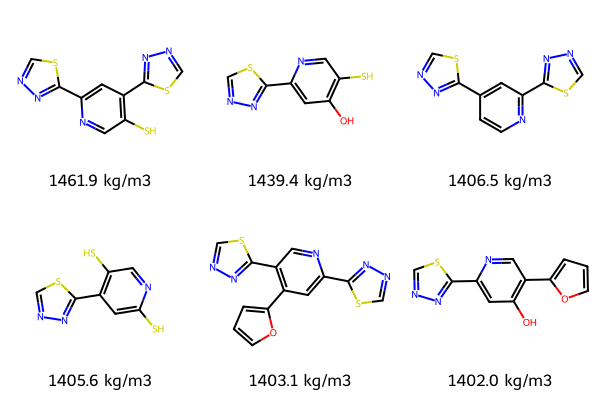

In [7]:
from rdkit import Chem
from rdkit.Chem import Draw

top = results.sort_values('Predicted density (kg/m3)', ascending=False).head(6)
Draw.MolsToGridImage([Chem.MolFromSmiles(s) for s in top['SMILES']], molsPerRow=3,
                     legends=[f'{d:.1f} kg/m3' for d in top['Predicted density (kg/m3)']])

The running best of the predicted density shows the progress of the search over the evaluated molecules.

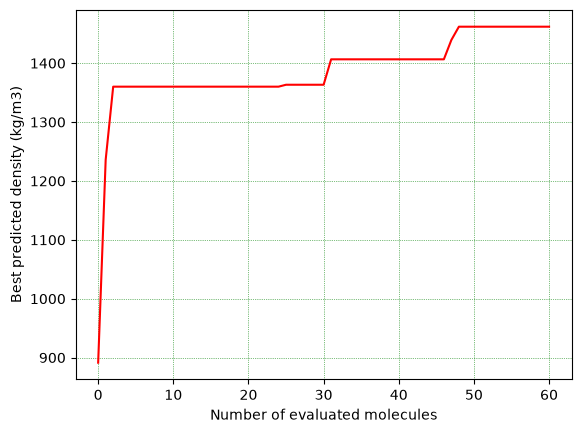

In [8]:
import matplotlib.pyplot as plt

plt.plot(results['Predicted density (kg/m3)'].cummax().values, color='red')
plt.xlabel('Number of evaluated molecules')
plt.ylabel('Best predicted density (kg/m3)')
plt.grid(color='green', linestyle=':', linewidth=0.5)
plt.show()

### Resume the search

Calling `ga.search` again continues from the stored population, which is useful when the objective function is expensive. Individuals that were already evaluated are not evaluated again.

In [9]:
ga.search(n_generations=3)
print(len(ga.fit_list), 'molecules evaluated in total')

Generation:   0%|          | 0/3 [00:00<?, ?gen/s]

90 molecules evaluated in total


### Saving each generation

If `output_dir` is provided, every generation is written to `<output_dir>/generation_<n>.csv` with the canonical SMILES and the fitness values of the new molecules. Alternatively, `ga.batch` writes the next set of molecules to `new_molecules.csv`, so that the properties can be computed outside of the notebook (for example, on a cluster) and passed back as `(individual, fitness tuple, smiles)` entries.